In [14]:
import cv2
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [15]:
def load_images(folder, csv_path):
    data = []
    labels = []
    df = pd.read_csv(csv_path)  
    
    for filename, label in zip(df.iloc[:, 0], df.iloc[:, 1]):
        img_path = os.path.join(folder, filename)
        img = cv2.imread(img_path)  
        
        if img is not None:
            data.append(img.flatten())
            labels.append(int(label))
            
    return np.array(data), np.array(labels)

In [ ]:
X_train, y_train = load_images('dataset_updated/224x224', 'dataset_updated/train/labels_train.csv')

In [12]:
X_val, y_val = load_images('dataset_updated/224x224', 'dataset_updated/validation/labels_val.csv')

In [ ]:
X_test, y_test = load_images('dataset_updated/224x224', 'dataset_updated/test/labels_test.csv')

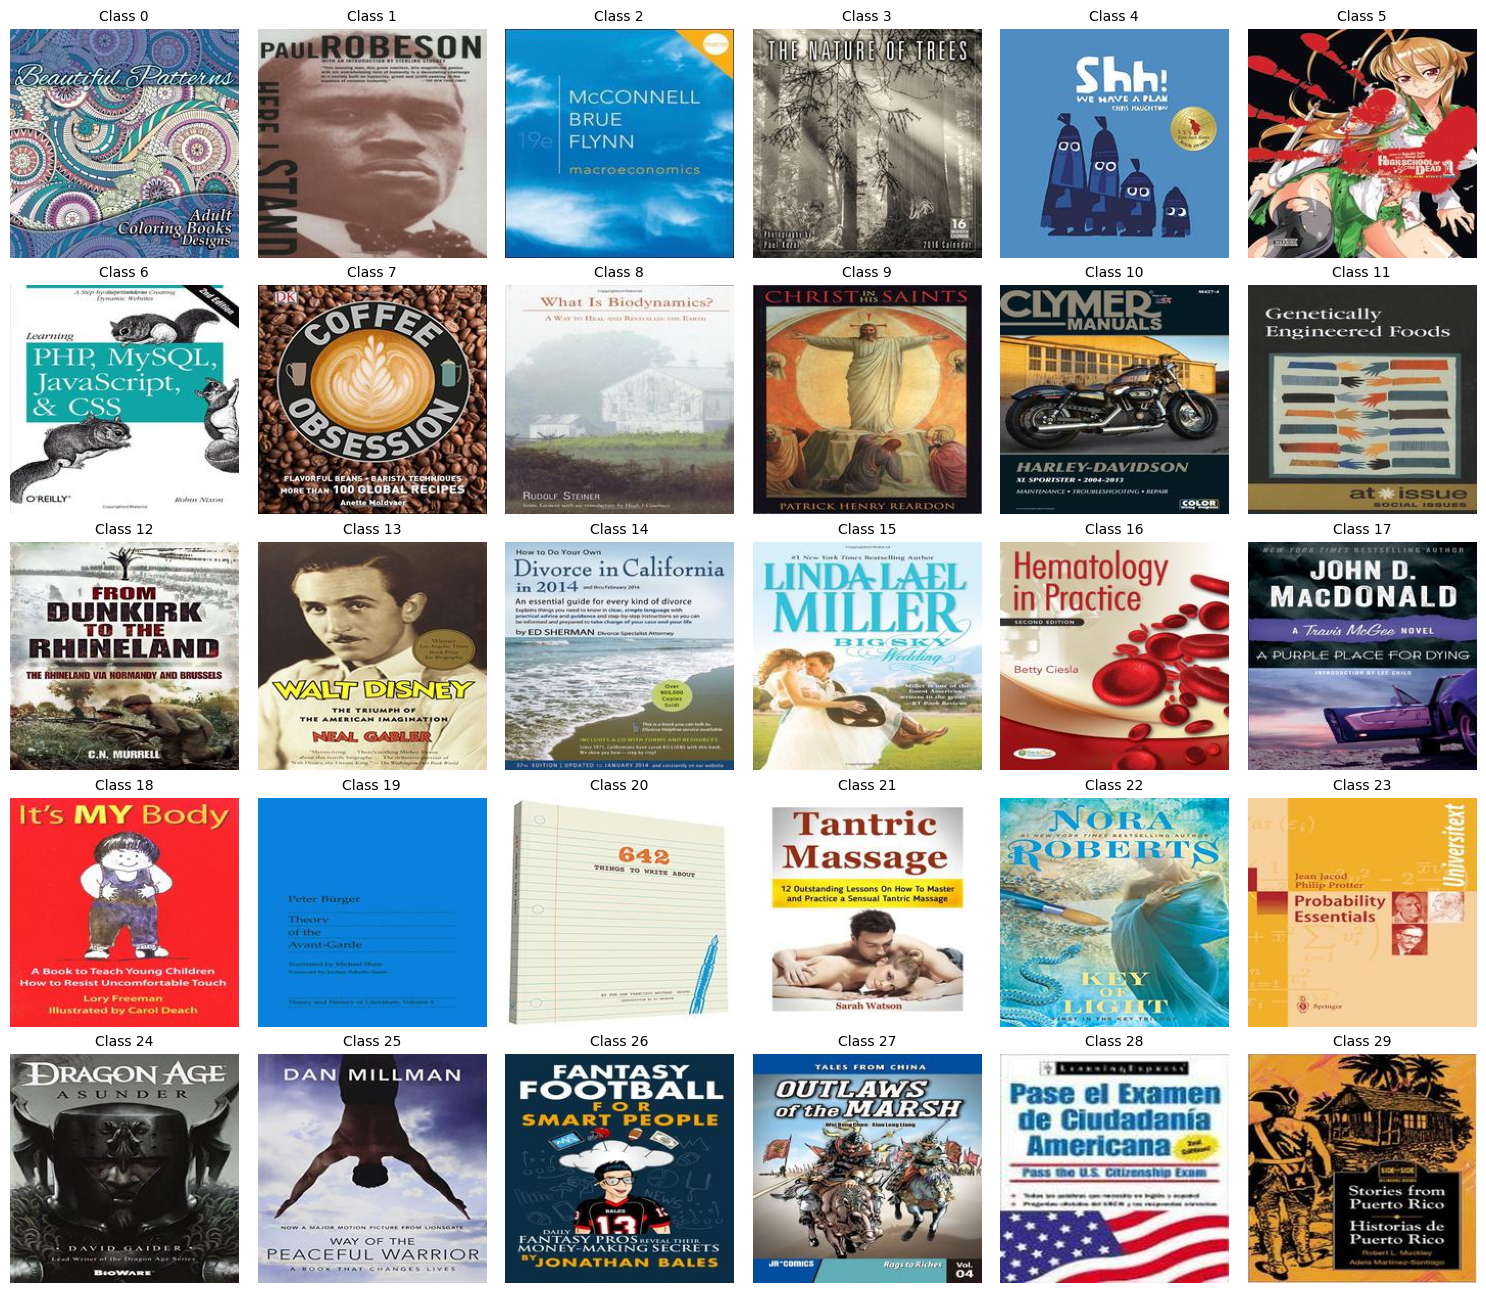

In [17]:
classes = np.unique(y_val)          

plt.figure(figsize=(15, 13))

for i, category in enumerate(classes):
    idx = np.random.choice(np.where(y_val == category)[0])   
    img = X_val[idx].reshape(224, 224, 3)[..., ::-1]         

    plt.subplot(5, 6, i + 1)
    plt.imshow(img)
    plt.title(f"Class {category}", fontsize=10)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score